# PfCSP figures

Every figure is drawn from the tables in `10_table_for_plot`, written by step 7 of the
pipeline. Nothing here reads the pipeline output or recomputes a statistic, so a figure
can be redrawn, or drawn differently, without running the pipeline again.

Colours live in `plot_style.tsv`. To change one, edit that file and rerun step 7.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

REPO = Path("..").resolve()
OUT_DIR = Path("/home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_output")
TABLE_DIR = OUT_DIR / "10_table_for_plot"
FIG_DIR = OUT_DIR / "11_figures"

sys.path.insert(0, str(REPO / "notebook"))
sys.path.insert(0, str(REPO / "process"))
import csp_plots as P
import csp_protein_matrix

FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "font.size": 10})

T = P.load_tables(TABLE_DIR)
style = T["plot_style"]
print(T["index"].to_string(index=False))

figure                        file  rows                                                describes                written_by
  fig1      fig1_sample_counts.tsv     3                         Samples per country and controls process/07_plot_tables.py
  fig2                fig2_moi.tsv   184            MOI per sample by state, with mean and median process/07_plot_tables.py
  fig3          fig3_diversity.tsv     4                       Nucleotide and haplotype diversity process/07_plot_tables.py
  fig4      fig4_substitutions.tsv  2347 Heterozygosity, presence grid and prevalence by position process/07_plot_tables.py
  fig7      fig7_vaccine_match.tsv    42                               Vaccine match, five panels process/07_plot_tables.py
  fig8          fig8_structure.tsv   184              FST by state, FST by country, PCoA with 3D7 process/07_plot_tables.py
 fig10  fig10_tree_annotations.tsv    11                          iTOL files and their load order process/07_plot_tables.py
 clone  

## Figure 1, samples per country

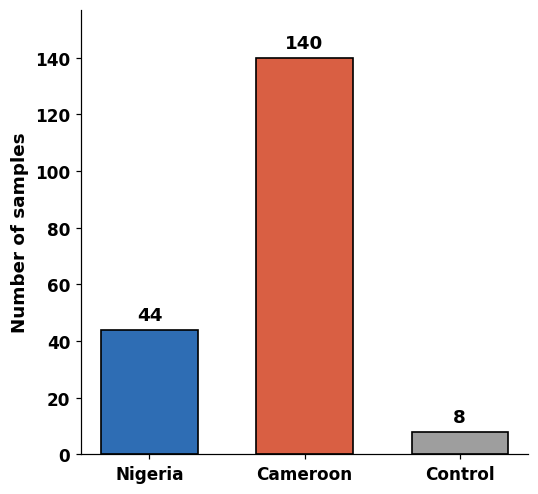

In [2]:
fig1 = P.fig_sample_counts(T["fig1_sample_counts"], style)
fig1.savefig(FIG_DIR / "fig1_sample_counts.png", dpi=300)
plt.show()

## Figure 2, multiplicity of infection by state

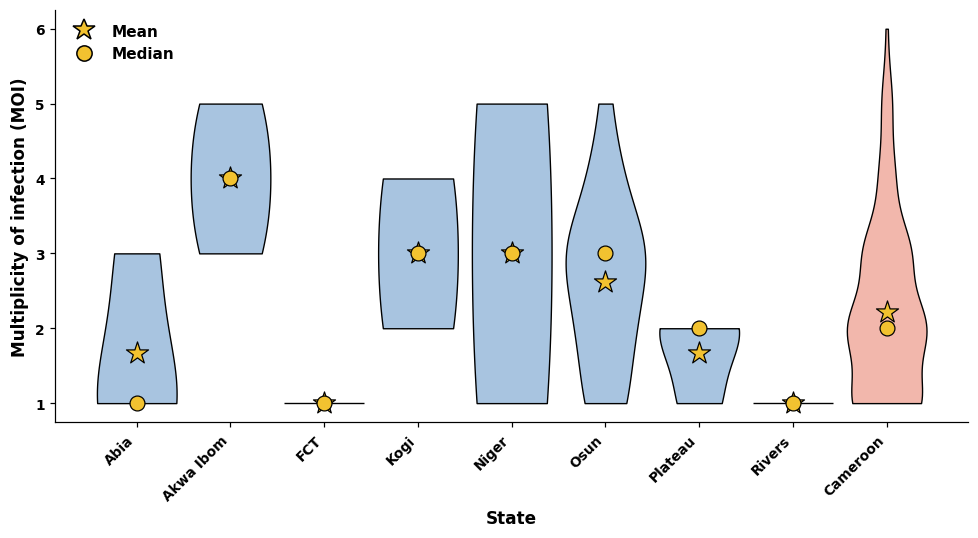

             n  mean  median  low  high
x                                      
Abia         3  1.67     1.0  1.0   3.0
Akwa Ibom    3  4.00     4.0  3.0   5.0
Cameroon   126  2.22     2.0  1.0   6.0
FCT          3  1.00     1.0  1.0   1.0
Kogi         2  3.00     3.0  2.0   4.0
Niger        2  3.00     3.0  1.0   5.0
Osun        21  2.62     3.0  1.0   5.0
Plateau      3  1.67     2.0  1.0   2.0
Rivers       3  1.00     1.0  1.0   1.0


In [3]:
fig2 = P.fig_moi(T["fig2_moi"], style)
fig2.savefig(FIG_DIR / "fig2_moi_by_state.png", dpi=300)
plt.show()

pts = T["fig2_moi"].query("panel == 'points'")
print(pts.groupby("x")["value"]
         .agg(n="size", mean="mean", median="median", low="min", high="max")
         .round(2).to_string())

## Figure 3, nucleotide and haplotype diversity

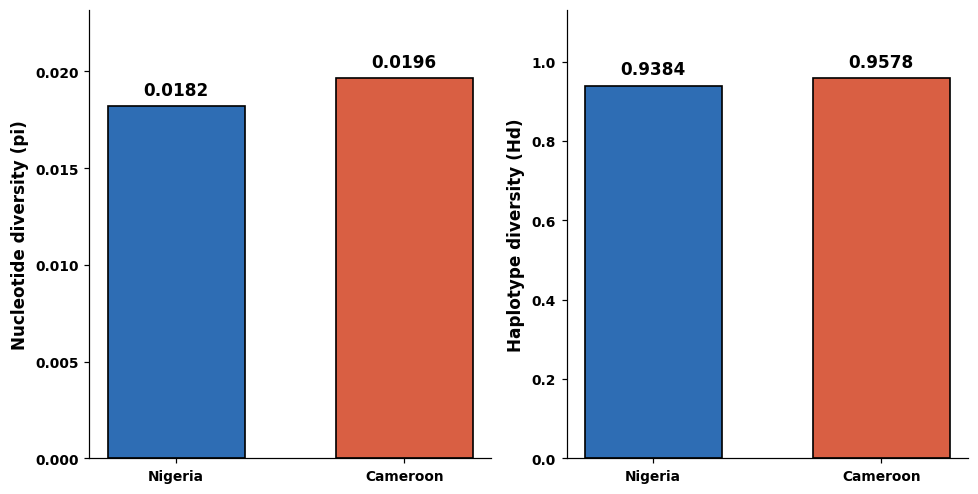

panel   series    value   n  n_haplotypes
    A  Nigeria 0.018185  95            36
    A Cameroon 0.019638 279            72
    B  Nigeria 0.938410  95            36
    B Cameroon 0.957840 279            72


In [4]:
fig3 = P.fig_diversity(T["fig3_diversity"], style)
fig3.savefig(FIG_DIR / "fig3_diversity.png", dpi=300)
plt.show()

print(T["fig3_diversity"][["panel", "series", "value", "n", "n_haplotypes"]]
      .to_string(index=False))

## Figure 4, where the variation sits

Panel A carries two denominators. `value` uses the metadata count, which is what the
figure has always shown. `n_with_consensus` is the stricter denominator, the samples that
actually returned a consensus, so the fraction can be recomputed without rerunning.

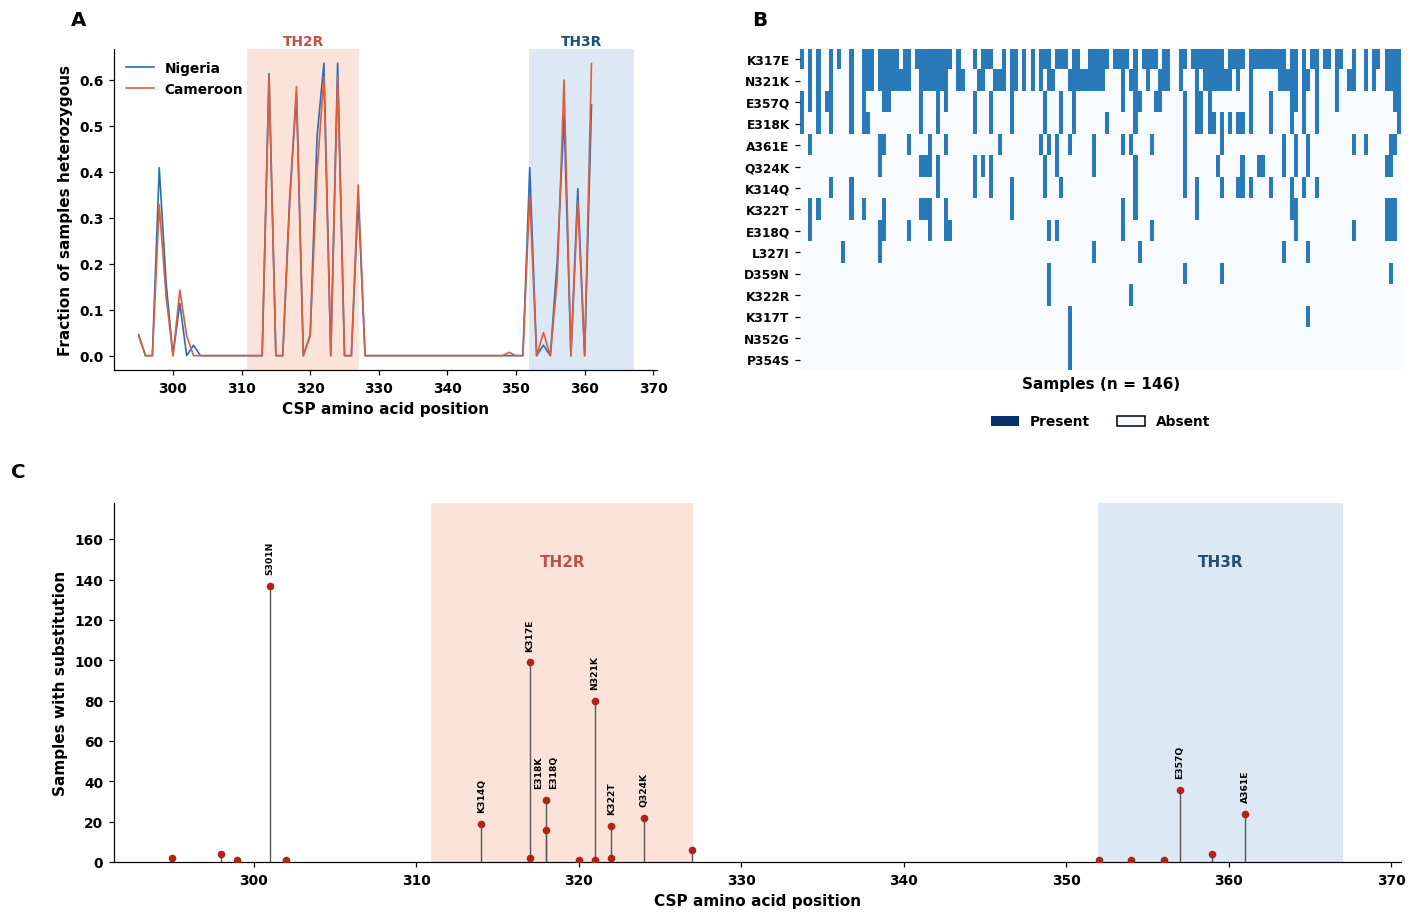

          n_denominator  n_with_consensus
series                                   
Cameroon          140.0             126.0
Nigeria            44.0              42.0


In [5]:
fig4 = P.fig_substitutions(T["fig4_substitutions"], style)
fig4.savefig(FIG_DIR / "fig4_substitutions.png", dpi=300)
plt.show()

a = T["fig4_substitutions"].query("panel == 'A'")
print(a.groupby("series")[["n_denominator", "n_with_consensus"]].first().to_string())

## Figure 7, distance from the 3D7 vaccine antigen

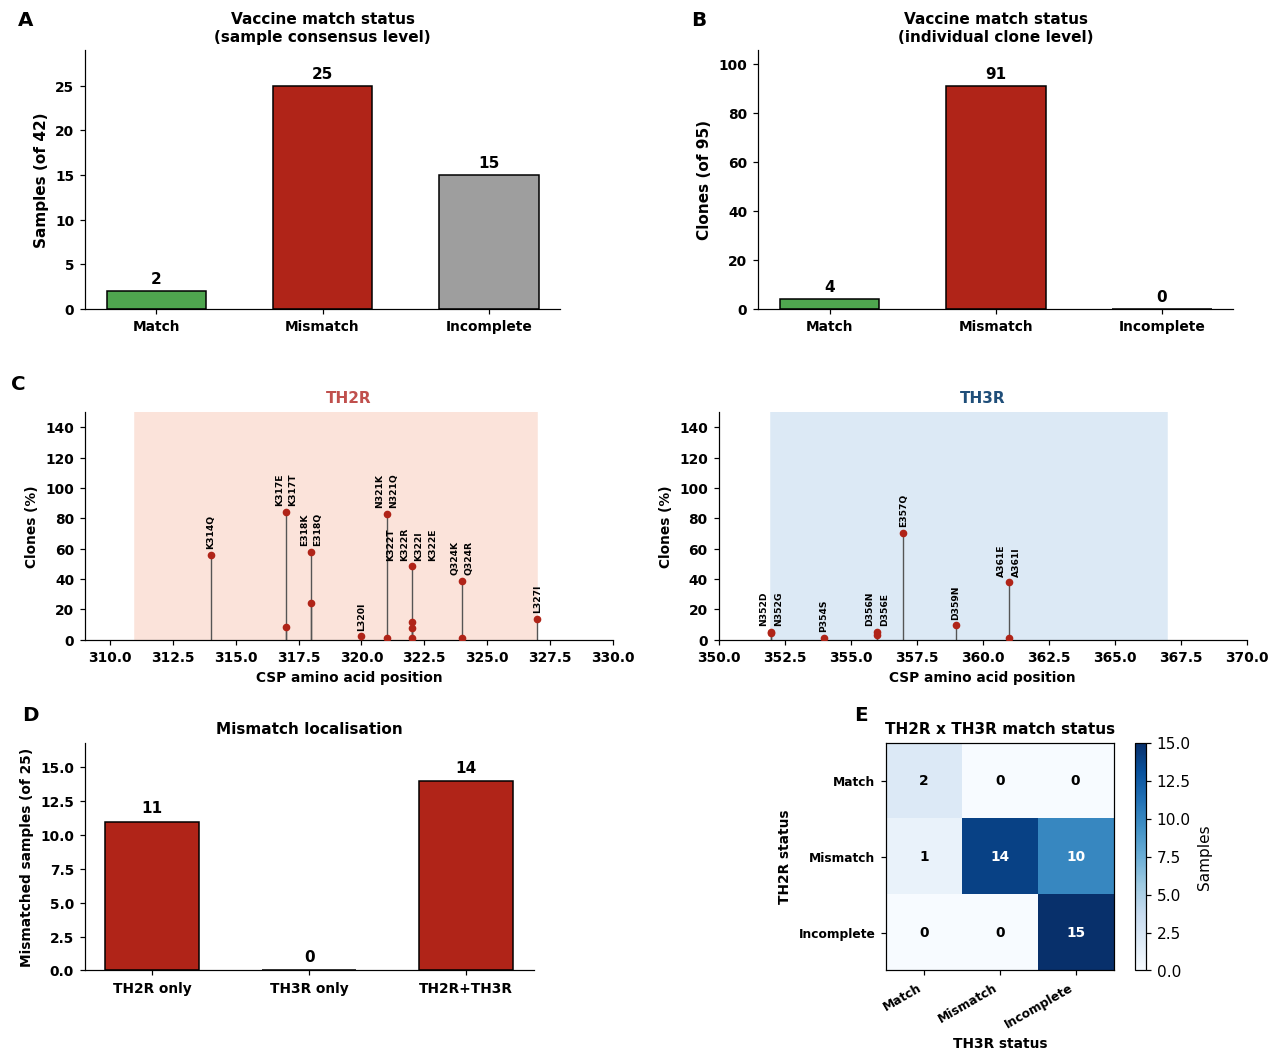

A {'match': 2.0, 'mismatch': 25.0, 'incomplete': 15.0}
B {'match': 4.0, 'mismatch': 91.0, 'incomplete': 0.0}
D {'TH2R only': 11.0, 'TH3R only': 0.0, 'TH2R+TH3R': 14.0}


In [6]:
fig7 = P.fig_vaccine_match(T["fig7_vaccine_match"], style)
fig7.savefig(FIG_DIR / "fig7_vaccine_match.png", dpi=300)
plt.show()

for panel in ("A", "B", "D"):
    d = T["fig7_vaccine_match"].query("panel == @panel")
    print(panel, dict(zip(d.series, d.value)))

## Figure 8, population structure and the PCoA with 3D7

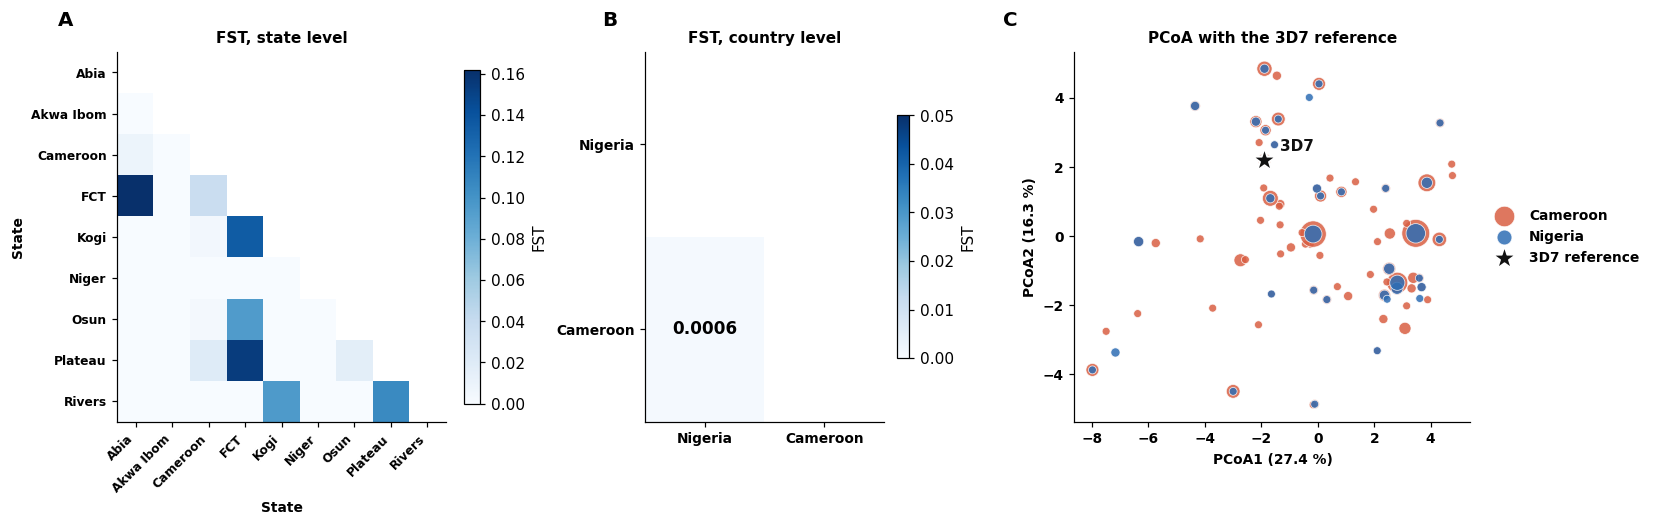

series   value
 PCoA1 27.3854
 PCoA2 16.3102
country FST: [0.000631]


In [7]:
fig8 = P.fig_structure(T["fig8_structure"], style)
fig8.savefig(FIG_DIR / "fig8_structure.png", dpi=300)
plt.show()

t8 = T["fig8_structure"]
print(t8.query("panel == 'C_meta'")[["series", "value"]].to_string(index=False))
print("country FST:", t8.query("panel == 'B'").value.tolist())

## Figure 9, the protein matrix against 3D7

Rebuilt from its four tables. The layout code is unchanged, it simply reads the records
back instead of recomputing them.

[INFO] figure 7.50 x 9.30 in, rebuilt from /home/gueyekhadim/work/data/malaria_team/Output_Analysis_Data/ICEMR_CRID_CSP_output/10_table_for_plot


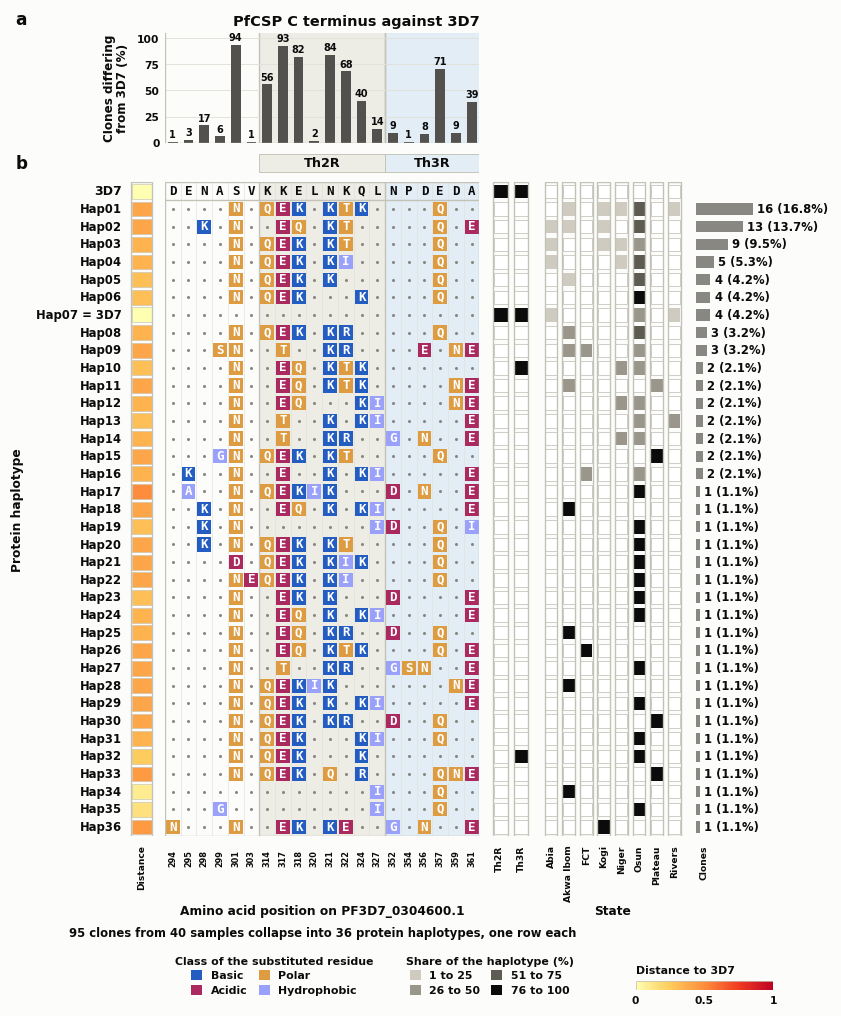

In [8]:
fig9 = csp_protein_matrix.draw_from_tables(
    TABLE_DIR,
    out_pdf=FIG_DIR / "csp_protein_vs_3d7.pdf",
    out_png=FIG_DIR / "csp_protein_vs_3d7.png")
plt.show()

## Figure 10, the phylogeny

The tree is drawn in iTOL, not here. Load the files in this order.

In [9]:
t10 = T["fig10_tree_annotations"]
for _, r in t10.iterrows():
    mark = " " if r.present else "  MISSING"
    print(f"{r.panel:<12}{r.series:<34}{r.label}{mark}")

tree        nigeria.rooted.nwk                the tree itself 
labels      itol_labelcolors_origin.txt       label colour, no ring 
ring 1      itol_ringlabel_origin.txt         ring title 
ring 1      itol_colorstrip_origin.txt        origin of the haplotype 
ring 2      itol_ringlabel_our_clones.txt     ring title 
ring 2      itol_symbol_our_clones.txt        clones in our samples, circles 
ring 3      itol_ringlabel_region.txt         ring title 
ring 3      itol_piechart_by_region.txt       region of the Pf8 samples 
ring 4      itol_ringlabel_country.txt        ring title 
ring 4      itol_piechart_by_country.txt      country of the Pf8 samples 
alternative itol_bar_our_clones.txt           the same counts as bars 
